Nikitha joshy

### Cleaning and Prep

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_excel("cs4_data.xlsx")
df.shape

(92, 19)

In [49]:
df.head(10)    # shows first 10 rows


,observation_date,FEDFUNDS,GS1,GS3,GS5,TERMCBAUTO48NS,TOTALSA,IPMAN,BUSLOANS,TOTALSL,TOTBKCR_avg,TOTBKCR_end,DRTSCILM,IPDMAN,CUMFNS,IPG3361T3S,CPIAUCSL,UNRATE,GDPC1
0,2018-01-01,1.41,1.80,2.15,2.38,4.74,17.176,100.2477,2109.5759,3847813.38,12570.061220,12578.5406,-10.0,101.4646,77.3713,101.6761,248.859,4.0,20044.077
1,2018-02-01,1.42,1.96,2.36,2.60,4.74,17.447,101.1191,2112.0245,3863785.50,12579.692075,12591.9205,-10.0,102.5797,78.0999,104.4171,249.529,4.1,20044.077
2,2018-03-01,1.51,2.06,2.42,2.63,4.74,17.662,101.0662,2123.2264,3876055.39,12588.964725,12597.1253,-10.0,102.8907,78.1015,106.7221,249.577,4.0,20044.077
3,2018-04-01,1.69,2.15,2.52,2.70,4.74,17.584,101.8102,2167.1125,3883468.07,12650.677600,12661.0759,-11.3,103.6534,78.6920,106.5235,250.227,4.0,20150.476
4,2018-05-01,1.70,2.27,2.66,2.82,5.05,17.829,100.9597,2173.6766,3900522.39,12681.275200,12710.9582,-11.3,102.4012,78.0687,98.4895,250.792,3.8,20150.476
5,2018-06-01,1.82,2.33,2.65,2.78,5.05,17.743,101.7171,2191.1233,3902512.63,12757.575500,12792.0451,-11.3,103.6748,78.6317,104.6103,251.018,4.0,20150.476
6,2018-07-01,1.91,2.39,2.70,2.78,5.05,17.629,101.7427,2204.0928,3924685.75,12800.542700,12815.0435,-15.9,102.8441,78.6973,99.7209,251.214,3.8,20276.154
7,2018-08-01,1.91,2.45,2.71,2.77,5.05,17.564,101.9949,2209.5556,3945881.88,12815.129860,12829.8774,-15.9,103.7095,78.9186,103.9349,251.663,3.8,20276.154
8,2018-09-01,1.95,2.56,2.84,2.89,5.05,17.776,102.0195,2225.8849,3957685.36,12857.334975,12866.4219,-15.9,103.7877,78.9586,106.3250,252.182,3.7,20276.154
9,2018-10-01,2.19,2.65,2.94,3.00,5.05,17.991,101.5510,2250.5491,3976272.51,12906.350100,12919.6739,-15.9,103.4533,78.5991,104.4291,252.772,3.8,20304.874


In [50]:


BASE_MONTH = '2019-12'   
DATE_COL   = 'observation_date'
CPI_COL    = 'CPIAUCSL'

adjust_cols = ['TOTALSL', 'BUSLOANS', 'TOTALSA', 'CUMFNS']


norm_only_cols = ['GDPC1', 'IPMAN', 'IPG3361T35']


df[DATE_COL] = pd.to_datetime(df[DATE_COL])
df['_period'] = df[DATE_COL].dt.to_period('M')
BASE_PERIOD = pd.Period(BASE_MONTH, 'M')

if not (df['_period'] == BASE_PERIOD).any():
    raise ValueError(f"Base period {BASE_MONTH} not found in {DATE_COL}.")

if CPI_COL not in df.columns:
    raise ValueError(f"CPI column '{CPI_COL}' not found in df.")

base_cpi = df.loc[df['_period'] == BASE_PERIOD, CPI_COL].iloc[0]

# Deflate + normalize nominal series 
adj_present = [c for c in adjust_cols if c in df.columns]
for col in adj_present:
    real_col  = f'{col}_real'
    index_col = f'{col}_index'
    # real (2019-12 dollars)
    df[real_col] = df[col] * (base_cpi / df[CPI_COL])
    # normalized to 2019-12 = 100
    base_val = df.loc[df['_period'] == BASE_PERIOD, real_col].iloc[0]
    df[index_col] = (df[real_col] / base_val) * 100


norm_present = [c for c in norm_only_cols if c in df.columns]
for col in norm_present:
    index_col = f'{col}_index'
    base_val = df.loc[df['_period'] == BASE_PERIOD, col].iloc[0]
    df[index_col] = (df[col] / base_val) * 100


#  Unchanged originals = all columns EXCEPT originals 
unchanged = [c for c in df.columns
             if not c.endswith('_real') and not c.endswith('_index')
             and c not in (adj_present + norm_present)]


KEEP_BOTH_FOR_ADJUSTED = False

new_versions = []
if KEEP_BOTH_FOR_ADJUSTED:
    new_versions += [f'{c}_real'  for c in adj_present]
    new_versions += [f'{c}_index' for c in adj_present]
else:
    new_versions += [f'{c}_index' for c in adj_present]


new_versions += [f'{c}_index' for c in norm_present]

# Final df
cols_final = [DATE_COL] + [c for c in unchanged if c != DATE_COL] + new_versions
# keep  original 
df_raw = df.copy()

df_norm = df[cols_final].copy()
df = df_norm


df.head()


,observation_date,FEDFUNDS,GS1,GS3,GS5,TERMCBAUTO48NS,TOTBKCR_avg,TOTBKCR_end,DRTSCILM,IPDMAN,IPG3361T3S,CPIAUCSL,UNRATE,_period,TOTALSL_index,BUSLOANS_index,TOTALSA_index,CUMFNS_index,GDPC1_index,IPMAN_index
0,2018-01-01,1.41,1.80,2.15,2.38,4.74,12570.061220,12578.5406,-10.0,101.4646,101.6761,248.859,4.0,2018-01,95.389033,92.992931,102.054683,104.290258,95.514172,101.080400
1,2018-02-01,1.42,1.96,2.36,2.60,4.74,12579.692075,12591.9205,-10.0,102.5797,104.4171,249.529,4.1,2018-02,95.527801,92.850887,103.386539,104.989689,95.514172,101.959039
2,2018-03-01,1.51,2.06,2.42,2.63,4.74,12588.964725,12597.1253,-10.0,102.8907,106.7221,249.577,4.0,2018-03,95.812730,93.325404,104.640446,104.971648,95.514172,101.905699
3,2018-04-01,1.69,2.15,2.52,2.70,4.74,12650.677600,12661.0759,-11.3,103.6534,106.5235,250.227,4.0,2018-04,95.746601,95.006960,103.907708,105.490564,96.021186,102.655879
4,2018-05-01,1.70,2.27,2.66,2.82,5.05,12681.275200,12710.9582,-11.3,102.4012,98.4895,250.792,3.8,2018-05,95.950423,95.080046,105.118115,104.419226,96.021186,101.798315


In [51]:
df.shape

(92, 20)

| Column                           | Description                                                                | Category                                   | Units / Meaning                                                                                            |
| -------------------------------- | -------------------------------------------------------------------------- | ------------------------------------------ | ---------------------------------------------------------------------------------------------------------- |
| **observation_date**             | Date of the monthly observation                                            | —                                          | Usually first day of the month (e.g., 2018-01-01)                                                          |
| **FEDFUNDS**                     | *Effective Federal Funds Rate*                                             | **Monetary Policy Variable**               | The key short-term interest rate the Fed controls. Shows policy stance — higher = tighter monetary policy. |
| **GS1**, **GS3**, **GS5**        | *Treasury Yields (1-year, 3-year, 5-year)*                                 | **Interest Rates / Yield Curve**           | Market-determined rates that respond to Fed policy. Useful for transmission of monetary stance.            |
| **TERMCBAUTO48NS**               | *Interest Rate on 48-month New Car Loans*                                  | **Auto Credit Conditions**                 | Cost of financing consumer auto loans — directly relevant for auto credit outcomes.                        |
| **TOTBKCR_avg**, **TOTBKCR_end** | *Total Bank Credit (average & end of month)*                               | **Bank Lending**                           | Total credit extended by commercial banks; higher values mean looser lending or credit expansion.          |
| **DRTSCILM**                     | *Net % of Banks Tightening Standards for C&I Loans (Medium & Large Firms)* | **Credit Standards / Bank Lending Survey** | Positive values mean *tightening* standards (harder to get loans). Negative means *easing*.                |
| **IPDMAN**                       | *Industrial Production: Manufacturing*                                     | **Real Activity (Manufacturing)**          | Measures the output of manufacturing — a proxy for durable goods production.                               |
| **IPG3361T35**                   | *Industrial Production: Motor Vehicles and Parts*                          | **Durable Goods Activity (Auto Sector)**   | More specific subset of manufacturing focusing on autos.                                                   |
| **CPIAUCSL**                     | *Consumer Price Index (All Urban Consumers, SA)*                           | **Inflation Index**                        | Used to convert nominal values to real (inflation-adjusted) values.                                        |
| **UNRATE**                       | *Unemployment Rate*                                                        | **Labor Market Indicator**                 | Overall macroeconomic condition — not central to assignment, but useful for context.                       |
| **_period**                      | Derived string for date formatting                                         | —                                          | Often used to label charts like "2018-01".                                                                 |


| Column             | Description                                                    | Interpretation                                        |
| ------------------ | -------------------------------------------------------------- | ----------------------------------------------------- |
| **TOTALSL_index**  | Real, normalized *Total Consumer Loans & Leases*               | Tracks consumer credit expansion/contraction.         |
| **BUSLOANS_index** | Real, normalized *Commercial & Industrial Loans*               | Captures business credit trends.                      |
| **TOTALSA_index**  | Real, normalized *Auto Sales or Auto Loan Volume*              | Reflects strength of consumer auto financing.         |
| **CUMFNS_index**   | Real, normalized *Consumer Credit Outstanding (Non-Revolving)* | Longer-term consumer lending (e.g., car loans).       |
| **GDPC1_index**    | Real, normalized *Gross Domestic Product*                      | Overall economic activity baseline.                   |
| **IPMAN_index**    | Real, normalized *Manufacturing Output*                        | Durable goods production and manufacturing intensity. |


### Auto

In [52]:
for c in df.columns:
    print(repr(c))


'observation_date'
'FEDFUNDS'
'GS1'
'GS3'
'GS5'
'TERMCBAUTO48NS'
'TOTBKCR_avg'
'TOTBKCR_end'
'DRTSCILM'
'IPDMAN'
'IPG3361T3S'
'CPIAUCSL'
'UNRATE'
'_period'
'TOTALSL_index'
'BUSLOANS_index'
'TOTALSA_index'
'CUMFNS_index'
'GDPC1_index'
'IPMAN_index'


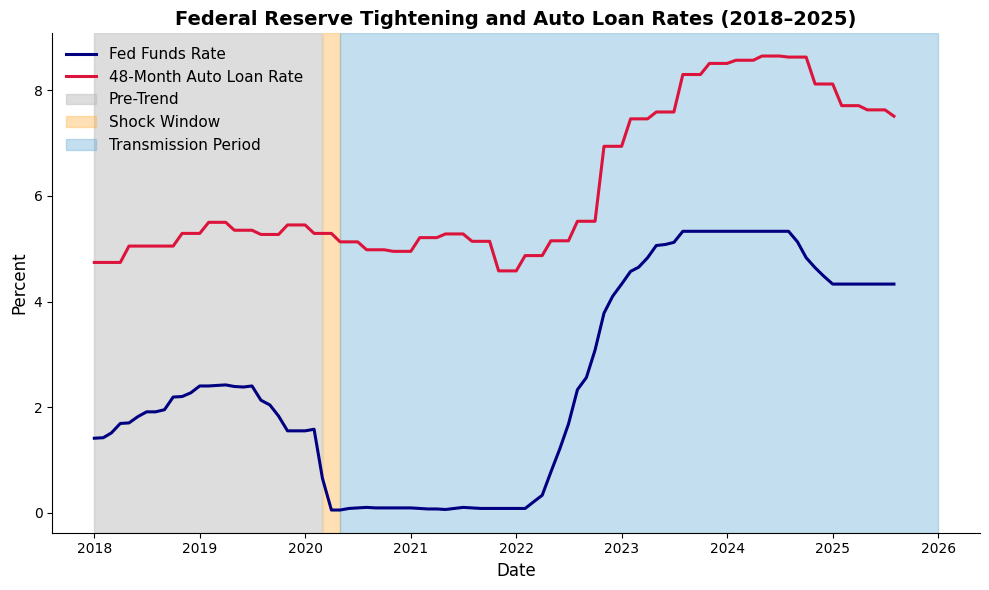

In [53]:


# Define shading periods
pre_start, pre_end = '2018-01-01', '2020-03-01'
shock_start, shock_end = '2020-03-02', '2020-04-30'
trans_start, trans_end = '2020-05-01', '2025-12-31'


plt.figure(figsize=(10,6))


plt.plot(df['observation_date'], df['FEDFUNDS'], 
         label='Fed Funds Rate', color='navy', linewidth=2.2)
plt.plot(df['observation_date'], df['TERMCBAUTO48NS'], 
         label='48-Month Auto Loan Rate', color='crimson', linewidth=2.2)

# Add shaded regions 
plt.axvspan(pre_start, pre_end, color='#bdbdbd', alpha=0.5, label='Pre-Trend')          # dark gray
plt.axvspan(shock_start, shock_end, color='#ffb347', alpha=0.4, label='Shock Window')   # orange
plt.axvspan(trans_start, trans_end, color='#6baed6', alpha=0.4, label='Transmission Period')  # stronger blue

# Titles and labels
plt.title('Federal Reserve Tightening and Auto Loan Rates (2018–2025)', fontsize=14, weight='bold')
plt.ylabel('Percent', fontsize=12)
plt.xlabel('Date', fontsize=12)

# Legend and layout
plt.legend(frameon=False, fontsize=11)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.grid(False)
plt.tight_layout()
plt.show()


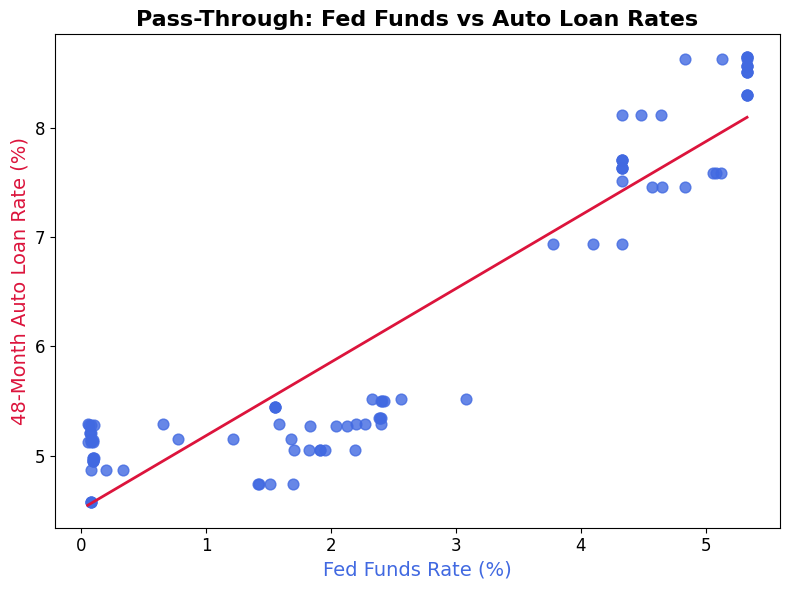

In [54]:

plt.figure(figsize=(8, 6))

sns.regplot(
    x='FEDFUNDS', y='TERMCBAUTO48NS', data=df,
    scatter_kws={'color': 'royalblue', 's': 60},   # Fed Funds (x-axis)
    line_kws={'color': 'crimson', 'linewidth': 2}, # Auto Loan Rate (y-axis)
    ci=None
)

plt.title('Pass-Through: Fed Funds vs Auto Loan Rates', fontsize=16, weight='bold')
plt.xlabel('Fed Funds Rate (%)', fontsize=14, color='royalblue')
plt.ylabel('48-Month Auto Loan Rate (%)', fontsize=14, color='crimson')
plt.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.show()


In [55]:
print(df.columns)


Index(['observation_date', 'FEDFUNDS', 'GS1', 'GS3', 'GS5', 'TERMCBAUTO48NS',
       'TOTBKCR_avg', 'TOTBKCR_end', 'DRTSCILM', 'IPDMAN', 'IPG3361T3S',
       'CPIAUCSL', 'UNRATE', '_period', 'TOTALSL_index', 'BUSLOANS_index',
       'TOTALSA_index', 'CUMFNS_index', 'GDPC1_index', 'IPMAN_index'],
      dtype='object')


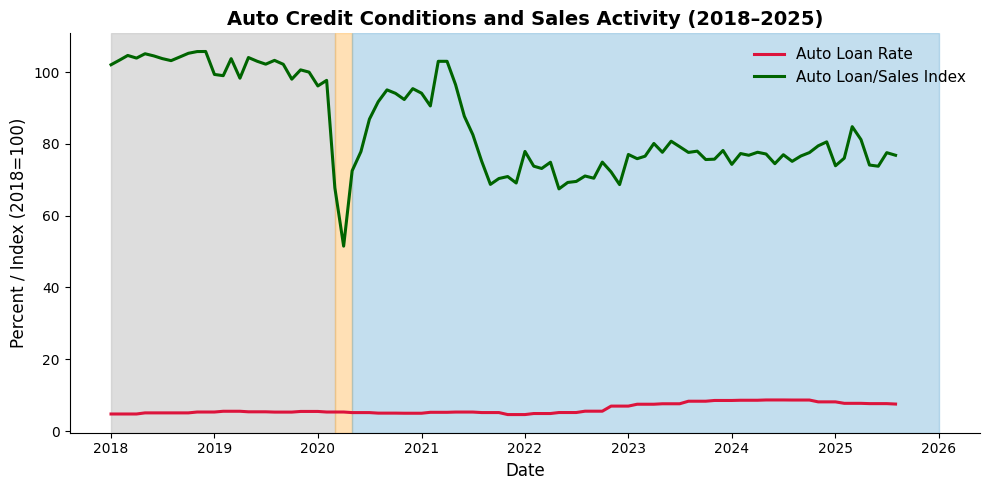

In [56]:
plt.figure(figsize=(10,5))
plt.plot(df['observation_date'], df['TERMCBAUTO48NS'], color='crimson', linewidth=2.2, label='Auto Loan Rate')
plt.plot(df['observation_date'], df['TOTALSA_index'], color='darkgreen', linewidth=2.2, label='Auto Loan/Sales Index')

# Shading
plt.axvspan(pre_start, pre_end, color='#bdbdbd', alpha=0.5)
plt.axvspan(shock_start, shock_end, color='#ffb347', alpha=0.4)
plt.axvspan(trans_start, trans_end, color='#6baed6', alpha=0.4)

plt.title('Auto Credit Conditions and Sales Activity (2018–2025)', fontsize=14, weight='bold')
plt.ylabel('Percent / Index (2018=100)', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.legend(frameon=False, fontsize=11)
plt.tight_layout()

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(False)
plt.show()


In [57]:
cols = ['FEDFUNDS', 'TERMCBAUTO48NS', 'TOTALSA_index', 'IPG3361T3S']
sub = df[cols].copy()

# Rename columns
sub.columns = [
    'Federal Funds Rate (Policy Rate)',
    '48-Month Auto Loan Rate (Consumer Credit Cost)',
    'Auto Loan/Sales Index (Credit Volume)',
    'Motor Vehicle Production Index (Real Output)'
]

#correlations
corr_with_fed = sub.corr().loc['Federal Funds Rate (Policy Rate)'].drop('Federal Funds Rate (Policy Rate)')
corr_table = corr_with_fed.to_frame('Correlation with Fed Funds')
print("=== Correlation of Key Variables with Federal Funds Rate (2018–2025) ===")
display(corr_table.round(2))


=== Correlation of Key Variables with Federal Funds Rate (2018–2025) ===


,Correlation with Fed Funds
48-Month Auto Loan Rate (Consumer Credit Cost),0.93
Auto Loan/Sales Index (Credit Volume),-0.27
Motor Vehicle Production Index (Real Output),0.41


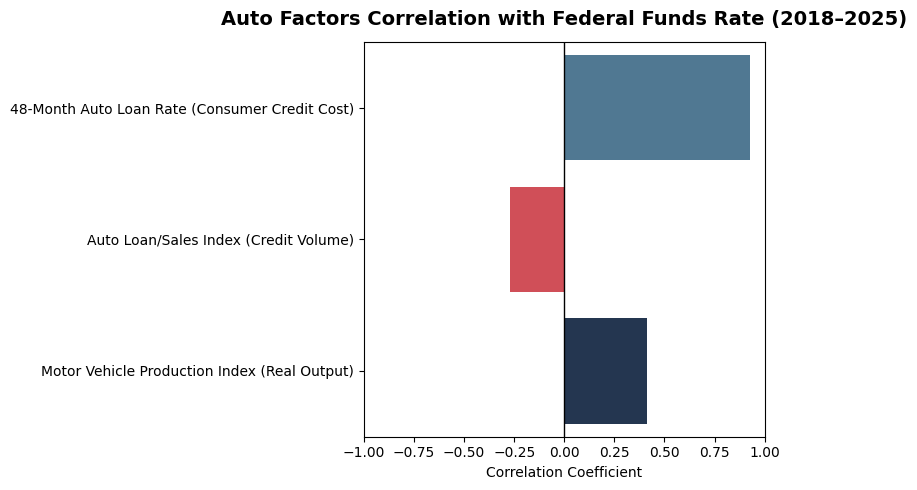

In [58]:

cols = ['FEDFUNDS', 'TERMCBAUTO48NS', 'TOTALSA_index', 'IPG3361T3S']
sub = df[cols].copy()
sub.columns = [
    'Federal Funds Rate (Policy Rate)',
    '48-Month Auto Loan Rate (Consumer Credit Cost)',
    'Auto Loan/Sales Index (Credit Volume)',
    'Motor Vehicle Production Index (Real Output)'
]

#correlations with Fed Funds
corr_with_fed = sub.corr().loc['Federal Funds Rate (Policy Rate)'].drop('Federal Funds Rate (Policy Rate)')

colors = []
for var in corr_with_fed.index:
    if 'Auto Loan/Sales' in var:
        colors.append('#e63946')  #  red 
    elif 'Loan Rate' in var:
        colors.append('#457b9d')  # blue
    else:
        colors.append('#1d3557')  #  navy 

# Plot
plt.figure(figsize=(8,5))
sns.barplot(
    x=corr_with_fed.values,
    y=corr_with_fed.index,
    palette=colors,
    orient='h'
)

plt.title(
    'Auto Factors Correlation with Federal Funds Rate (2018–2025)',
    fontsize=14, weight='bold', pad=12
)
plt.xlabel('Correlation Coefficient')
plt.ylabel('')
plt.axvline(0, color='black', linewidth=1)
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()

In [59]:
print(df.columns)


Index(['observation_date', 'FEDFUNDS', 'GS1', 'GS3', 'GS5', 'TERMCBAUTO48NS',
       'TOTBKCR_avg', 'TOTBKCR_end', 'DRTSCILM', 'IPDMAN', 'IPG3361T3S',
       'CPIAUCSL', 'UNRATE', '_period', 'TOTALSL_index', 'BUSLOANS_index',
       'TOTALSA_index', 'CUMFNS_index', 'GDPC1_index', 'IPMAN_index'],
      dtype='object')


### Bank Lending Standards

In [60]:

df['observation_date'] = pd.to_datetime(df['observation_date'])


summary_tbl = (
    df.set_index('observation_date')
      .loc['2018':'2025', ['FEDFUNDS', 'TERMCBAUTO48NS', 'CUMFNS_index', 'DRTSCILM', 'BUSLOANS_index']]
      .resample('Y').mean().round(2)
)

# Rename columns 
summary_tbl.columns = [
    'Fed Funds Rate',
    'Auto Loan Rate',
    'Consumer Credit Index',
    'Banks Tightening (%)',
    'Business Loan Index'
]

print("=== Table 1. Annual Averages (2018–2025) ===")
display(summary_tbl)


=== Table 1. Annual Averages (2018–2025) ===


,Fed Funds Rate,Auto Loan Rate,Consumer Credit Index,Banks Tightening (%),Business Loan Index
observation_date,,,,,
2018-12-31,1.83,4.99,104.78,-13.28,95.90
2019-12-31,2.16,5.38,101.25,0.30,100.75
2020-12-31,0.38,5.13,94.18,37.60,114.85
2021-12-31,0.08,5.08,95.62,-15.05,101.10
2022-12-31,1.68,5.42,91.05,11.82,99.61
2023-12-31,5.02,7.83,86.08,43.88,99.85
2024-12-31,5.14,8.52,82.13,9.50,96.75
2025-12-31,4.33,7.71,80.15,11.64,91.55


In [61]:
corr_vars = ['FEDFUNDS','TERMCBAUTO48NS','CUMFNS_index','DRTSCILM','BUSLOANS_index']
corr = df[corr_vars].corr().round(2)
print("=== Table 2. Correlation Matrix: Policy, Credit Costs, and Lending ===")
display(corr)


=== Table 2. Correlation Matrix: Policy, Credit Costs, and Lending ===


,FEDFUNDS,TERMCBAUTO48NS,CUMFNS_index,DRTSCILM,BUSLOANS_index
FEDFUNDS,1.00,0.93,-0.64,0.33,-0.46
TERMCBAUTO48NS,0.93,1.00,-0.82,0.36,-0.34
CUMFNS_index,-0.64,-0.82,1.00,-0.45,0.10
DRTSCILM,0.33,0.36,-0.45,1.00,0.52
BUSLOANS_index,-0.46,-0.34,0.10,0.52,1.00


In [62]:

corr_vars = ['FEDFUNDS', 'TERMCBAUTO48NS', 'CUMFNS_index', 'DRTSCILM', 'BUSLOANS_index']
corr = df[corr_vars].corr().round(2)


fed_corr = corr['FEDFUNDS'].drop('FEDFUNDS').to_frame('Correlation with Fed Funds Rate')
fed_corr.index = [
    'Auto Loan Rate (TERMCBAUTO48NS)',
    'Consumer Credit Index (CUMFNS_index)',
    'Banks Tightening (%) (DRTSCILM)',
    'Business Loans Index (BUSLOANS_index)'
]

print("=== Table: Correlation with Federal Funds Rate ===")
display(fed_corr)


=== Table: Correlation with Federal Funds Rate ===


,Correlation with Fed Funds Rate
Auto Loan Rate (TERMCBAUTO48NS),0.93
Consumer Credit Index (CUMFNS_index),-0.64
Banks Tightening (%) (DRTSCILM),0.33
Business Loans Index (BUSLOANS_index),-0.46


In [63]:
print(df.columns)

Index(['observation_date', 'FEDFUNDS', 'GS1', 'GS3', 'GS5', 'TERMCBAUTO48NS',
       'TOTBKCR_avg', 'TOTBKCR_end', 'DRTSCILM', 'IPDMAN', 'IPG3361T3S',
       'CPIAUCSL', 'UNRATE', '_period', 'TOTALSL_index', 'BUSLOANS_index',
       'TOTALSA_index', 'CUMFNS_index', 'GDPC1_index', 'IPMAN_index'],
      dtype='object')


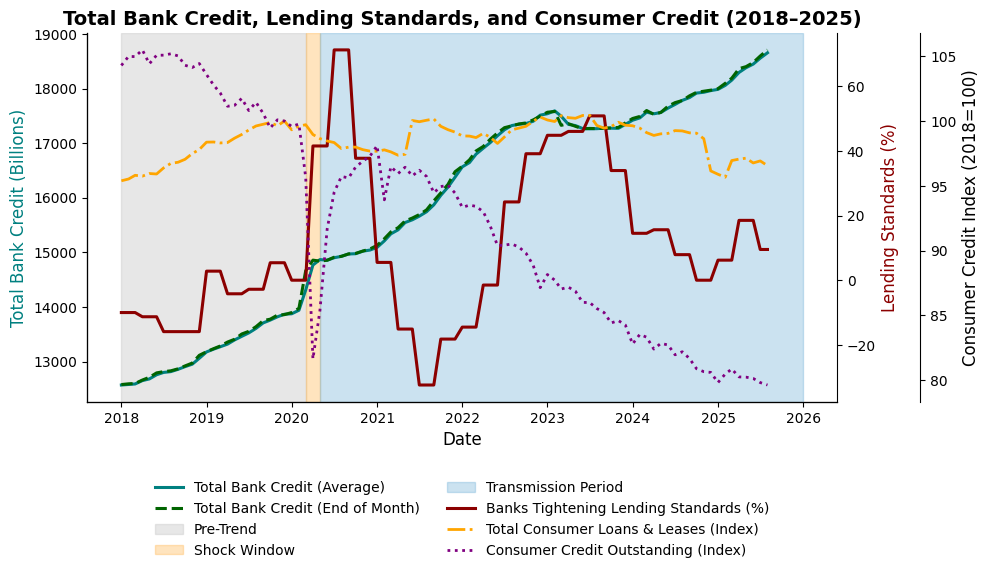

In [64]:
pre_start, pre_end   = '2018-01-01', '2020-03-01'
shock_start, shock_end = '2020-03-02', '2020-04-30'
trans_start, trans_end = '2020-05-01', '2025-12-31'

# Figure
fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(df['observation_date'], df['TOTBKCR_avg'],
         color='teal', linewidth=2.2, label='Total Bank Credit (Average)')
ax1.plot(df['observation_date'], df['TOTBKCR_end'],
         color='darkgreen', linewidth=2.2, linestyle='--',
         label='Total Bank Credit (End of Month)')
ax1.set_ylabel('Total Bank Credit (Billions)', fontsize=12, color='teal')

# Lending Standards
ax2 = ax1.twinx()
ax2.plot(df['observation_date'], df['DRTSCILM'],
         color='darkred', linewidth=2.2,
         label='Banks Tightening Lending Standards (%)')
ax2.set_ylabel('Lending Standards (%)', fontsize=12, color='darkred')

# Consumer indices
ax3 = ax1.twinx()
ax3.spines['right'].set_position(('outward', 60))
ax3.plot(df['observation_date'], df['TOTALSL_index'],
         color='orange', linewidth=2, linestyle='-.',
         label='Total Consumer Loans & Leases (Index)')
ax3.plot(df['observation_date'], df['CUMFNS_index'],
         color='purple', linewidth=2, linestyle=':',
         label='Consumer Credit Outstanding (Index)')
ax3.set_ylabel('Consumer Credit Index (2018=100)', fontsize=12)

# Shaded periods
for start, end, color, label in [
    (pre_start,  pre_end,  '#bdbdbd', 'Pre-Trend'),
    (shock_start, shock_end,'#ffb347', 'Shock Window'),
    (trans_start, trans_end,'#6baed6', 'Transmission Period'),
]:
    ax1.axvspan(start, end, color=color, alpha=0.35, label=label)


ax1.set_title('Total Bank Credit, Lending Standards, and Consumer Credit (2018–2025)',
              fontsize=14, weight='bold')
ax1.set_xlabel('Date', fontsize=12)
for a in (ax1, ax2, ax3):
    a.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)  
ax2.grid(False)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()
all_lines  = lines1 + lines2 + lines3
all_labels = labels1 + labels2 + labels3

ax1.legend(all_lines, all_labels,
           loc='upper center', bbox_to_anchor=(0.5, -0.18),
           ncol=2, frameon=False)

plt.tight_layout()
plt.show()


In [65]:
print(df.columns)

Index(['observation_date', 'FEDFUNDS', 'GS1', 'GS3', 'GS5', 'TERMCBAUTO48NS',
       'TOTBKCR_avg', 'TOTBKCR_end', 'DRTSCILM', 'IPDMAN', 'IPG3361T3S',
       'CPIAUCSL', 'UNRATE', '_period', 'TOTALSL_index', 'BUSLOANS_index',
       'TOTALSA_index', 'CUMFNS_index', 'GDPC1_index', 'IPMAN_index'],
      dtype='object')


### Manufacturing

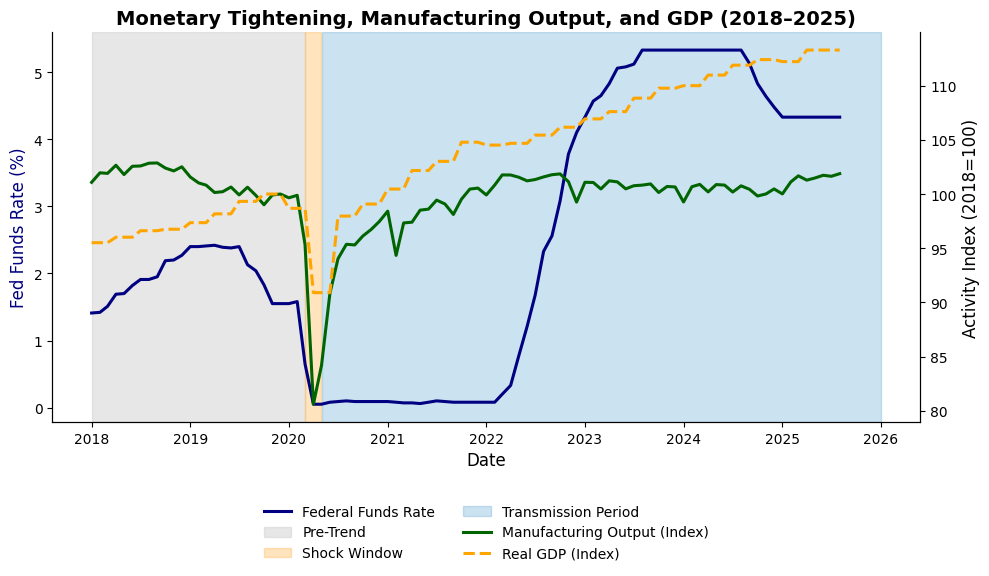

In [66]:

pre_start, pre_end = '2018-01-01', '2020-03-01'
shock_start, shock_end = '2020-03-02', '2020-04-30'
trans_start, trans_end = '2020-05-01', '2025-12-31'

# Plot
fig, ax1 = plt.subplots(figsize=(10,6))

# Fed Funds 
ax1.plot(df['observation_date'], df['FEDFUNDS'], color='navy', linewidth=2.2, label='Federal Funds Rate')
ax1.set_ylabel('Fed Funds Rate (%)', fontsize=12, color='navy')

#manufacturing & GDP
ax2 = ax1.twinx()
ax2.plot(df['observation_date'], df['IPMAN_index'], color='darkgreen', linewidth=2.2, label='Manufacturing Output (Index)')
ax2.plot(df['observation_date'], df['GDPC1_index'], color='orange', linewidth=2.2, linestyle='--', label='Real GDP (Index)')
ax2.set_ylabel('Activity Index (2018=100)', fontsize=12)

for start, end, color, label in [
    (pre_start, pre_end, '#bdbdbd', 'Pre-Trend'),
    (shock_start, shock_end, '#ffb347', 'Shock Window'),
    (trans_start, trans_end, '#6baed6', 'Transmission Period')
]:
    ax1.axvspan(start, end, color=color, alpha=0.35, label=label)

# Formatting
ax1.set_title('Monetary Tightening, Manufacturing Output, and GDP (2018–2025)',
              fontsize=14, weight='bold')
ax1.set_xlabel('Date', fontsize=12)
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.grid(False)

#legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.18),
            ncol=2, frameon=False)

plt.tight_layout()
plt.show()


In [67]:
print(df.columns)

Index(['observation_date', 'FEDFUNDS', 'GS1', 'GS3', 'GS5', 'TERMCBAUTO48NS',
       'TOTBKCR_avg', 'TOTBKCR_end', 'DRTSCILM', 'IPDMAN', 'IPG3361T3S',
       'CPIAUCSL', 'UNRATE', '_period', 'TOTALSL_index', 'BUSLOANS_index',
       'TOTALSA_index', 'CUMFNS_index', 'GDPC1_index', 'IPMAN_index'],
      dtype='object')


In [68]:

df = df.set_index('observation_date').sort_index()

PRE_START   = pd.Timestamp('2018-01-01')
PRE_END     = pd.Timestamp('2020-03-01')
SHOCK_START = pd.Timestamp('2020-03-02')
SHOCK_END   = pd.Timestamp('2020-04-30')
TRANS_START = pd.Timestamp('2020-05-01')
TRANS_END   = pd.Timestamp('2025-12-31')

mv_col = 'IPG3361T35' if 'IPG3361T35' in df.columns else 'IPG3361T3S'

# Label periods
def period_of(ts):
    if ts <= PRE_END:
        return 'Pre-Trend'
    elif SHOCK_START <= ts <= SHOCK_END:
        return 'Shock'
    else:
        return 'Transmission'

tmp = df[['FEDFUNDS','TERMCBAUTO48NS','IPDMAN', mv_col]].copy()
tmp['period'] = tmp.index.to_series().map(period_of)

# Period averages 
means_tbl = (
    tmp.groupby('period')[['FEDFUNDS','TERMCBAUTO48NS','IPDMAN', mv_col]]
       .mean()
       .round(2)
       .rename(columns={
           'FEDFUNDS':        'Fed Funds (avg, %)',
           'TERMCBAUTO48NS':  'Auto Loan Rate (avg, %)',
           'IPDMAN':          'IP: Manufacturing (avg)',
           mv_col:            'IP: Motor Vehicles & Parts (avg)'
       })
)

print("=== Table 1. Period Averages (Levels) ===")
display(means_tbl)


=== Table 1. Period Averages (Levels) ===


,"Fed Funds (avg, %)","Auto Loan Rate (avg, %)",IP: Manufacturing (avg),IP: Motor Vehicles & Parts (avg)
period,,,,
Pre-Trend,1.91,5.20,101.08,102.40
Shock,0.05,5.29,72.49,20.41
Transmission,2.79,6.63,98.77,100.95


#### general

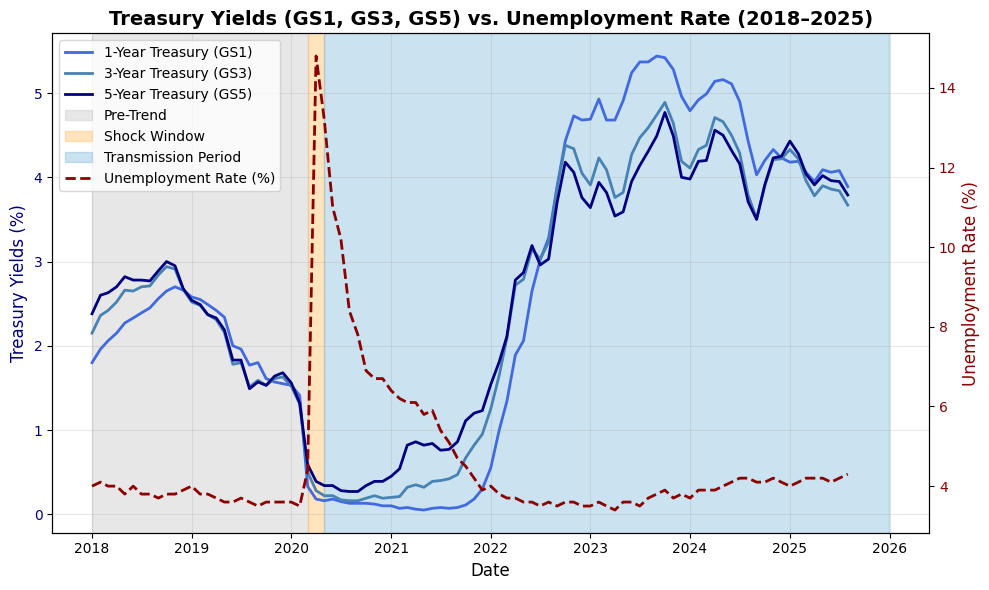

In [69]:


fig, ax1 = plt.subplots(figsize=(10, 6))
# Treasury yields
ax1.plot(df.index, df['GS1'], label='1-Year Treasury (GS1)', color='royalblue', linewidth=2)
ax1.plot(df.index, df['GS3'], label='3-Year Treasury (GS3)', color='steelblue', linewidth=2)
ax1.plot(df.index, df['GS5'], label='5-Year Treasury (GS5)', color='navy', linewidth=2)


ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Treasury Yields (%)', color='navy', fontsize=12)
ax1.tick_params(axis='y', labelcolor='navy')

# nemployment
ax2 = ax1.twinx()
ax2.plot(df.index, df['UNRATE'], label='Unemployment Rate (%)', color='darkred', linewidth=2, linestyle='--')
ax2.set_ylabel('Unemployment Rate (%)', color='darkred', fontsize=12)
ax2.tick_params(axis='y', labelcolor='darkred')

pre_start, pre_end = '2018-01-01', '2020-03-01'
shock_start, shock_end = '2020-03-02', '2020-04-30'
trans_start, trans_end = '2020-05-01', '2025-12-31'


for start, end, color, label in [
    (pre_start, pre_end, '#bdbdbd', 'Pre-Trend'),          
    (shock_start, shock_end, '#ffb347', 'Shock Window'),   
    (trans_start, trans_end, '#6baed6', 'Transmission Period')  
]:
    ax1.axvspan(start, end, color=color, alpha=0.35, label=label)


plt.title('Treasury Yields (GS1, GS3, GS5) vs. Unemployment Rate (2018–2025)', fontsize=14, weight='bold')
ax1.grid(alpha=0.3)

# legends 
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()
